# Credit Card Customer Segmentation

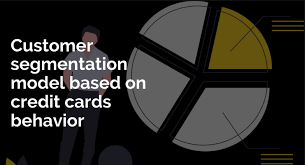

## Introduction 

Credit card companies use consumer's behaviors and demographics to target better their products. Behaviors can be tracked based on someone's purchasing and credit history. The goal of this analysis is to investigate the given dataset, and using K-means algorithms to segment a group for each client and also an explanation of the characteristics of each group and what are the main points that make them different. 

To achieve the goal, the analysis will follow the following steps:

1. Analyse the dataset
2. Prepare the daat for modeling
3. Find and appropiate numbers of clusters
4. Segment the data
5. Interpret and explain the reults

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
%matplotlib inline
import seaborn as sns
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


np.random.seed(42)
# Set figure size for the notebook
plt.rcParams["figure.figsize"]=12,8

sns.set_style('whitegrid')


<frozen importlib._bootstrap>:228: RuntimeWarning: scipy._lib.messagestream.MessageStream size changed, may indicate binary incompatibility. Expected 56 from C header, got 64 from PyObject


## Exploratory Data Analysis

After reading the data into pandas, it's time to explore it. Let's investigate the size of the dataset, what columns it contains, the type of values in each column, and also check on missing values.

In [2]:
customers = pd.read_csv('BankChurners.csv')

customers.head()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


In [3]:
pd.Series(customers.columns)

0                                             CLIENTNUM
1                                        Attrition_Flag
2                                          Customer_Age
3                                                Gender
4                                       Dependent_count
5                                       Education_Level
6                                        Marital_Status
7                                       Income_Category
8                                         Card_Category
9                                        Months_on_book
10                             Total_Relationship_Count
11                               Months_Inactive_12_mon
12                                Contacts_Count_12_mon
13                                         Credit_Limit
14                                  Total_Revolving_Bal
15                                      Avg_Open_To_Buy
16                                 Total_Amt_Chng_Q4_Q1
17                                      Total_Tr

To make the dataset more manageable we are going to use only those columns that are pertinent to the study and those columns that are empty

In [4]:
customers = customers.drop(['Card_Category','Contacts_Count_12_mon','Total_Revolving_Bal','Avg_Open_To_Buy','Total_Amt_Chng_Q4_Q1','Total_Ct_Chng_Q4_Q1','Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1','Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'], axis=1)

In [5]:
pd.Series(customers.columns)

0                    CLIENTNUM
1               Attrition_Flag
2                 Customer_Age
3                       Gender
4              Dependent_count
5              Education_Level
6               Marital_Status
7              Income_Category
8               Months_on_book
9     Total_Relationship_Count
10      Months_Inactive_12_mon
11                Credit_Limit
12             Total_Trans_Amt
13              Total_Trans_Ct
14       Avg_Utilization_Ratio
dtype: object

### Changing column names

In [6]:
#  Column names: remove white spaces and convert to lower case
customers.columns= customers.columns.str.strip().str.lower()
customers = customers.rename(columns={'clientnum':'customer_id','customer_age':'age'})
customers.columns

Index(['customer_id', 'attrition_flag', 'age', 'gender', 'dependent_count',
       'education_level', 'marital_status', 'income_category',
       'months_on_book', 'total_relationship_count', 'months_inactive_12_mon',
       'credit_limit', 'total_trans_amt', 'total_trans_ct',
       'avg_utilization_ratio'],
      dtype='object')

In [7]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               10127 non-null  int64  
 1   attrition_flag            10127 non-null  object 
 2   age                       10127 non-null  int64  
 3   gender                    10127 non-null  object 
 4   dependent_count           10127 non-null  int64  
 5   education_level           10127 non-null  object 
 6   marital_status            10127 non-null  object 
 7   income_category           10127 non-null  object 
 8   months_on_book            10127 non-null  int64  
 9   total_relationship_count  10127 non-null  int64  
 10  months_inactive_12_mon    10127 non-null  int64  
 11  credit_limit              10127 non-null  float64
 12  total_trans_amt           10127 non-null  int64  
 13  total_trans_ct            10127 non-null  int64  
 14  avg_ut

There are 10127 rows and 14 columns in the dataset including a unique identifier for each client, which is not going to be needed for the segmentation.

Of the 13 columns left, there are 8 columns containing integers, 2 containing floats, and 3 columns containing strings, which means we have 3 categorical columns to deal with.

Also, there are no missing values.

### Fixing income_category column to get integers instead of groups

The income_category column is a string of a range of income. Let's fix that

In [8]:
customers['income_category'].value_counts()

Less than $40K    3561
$40K - $60K       1790
$80K - $120K      1535
$60K - $80K       1402
Unknown           1112
$120K +            727
Name: income_category, dtype: int64

In [9]:
customers['income_category'].value_counts(normalize = True)

Less than $40K    0.351634
$40K - $60K       0.176755
$80K - $120K      0.151575
$60K - $80K       0.138442
Unknown           0.109805
$120K +           0.071788
Name: income_category, dtype: float64

In [10]:
corrected_salary = {
    'Less than $40K': 40000,
    '$40K - $60K': 50000,
    '$80K - $120K': 100000,
    '$60K - $80K': 70000,
    '$120K +': 120000   
}
customers['income_category'] = customers['income_category'].map(corrected_salary)
print(customers['income_category'])

0         70000.0
1         40000.0
2        100000.0
3         40000.0
4         70000.0
           ...   
10122     50000.0
10123     50000.0
10124     40000.0
10125     50000.0
10126     40000.0
Name: income_category, Length: 10127, dtype: float64


In [11]:
# Mapping the income_category introduced NaN values. Let's fix NaN values and change the column name
customers = customers.rename(columns={'income_category':'estimated_income'})
customers['estimated_income'].isnull().value_counts()

False    9015
True     1112
Name: estimated_income, dtype: int64

In [12]:
# Filling NaN values with income_category mean grouping by age. NaN vales were 11% of the data. Making this assumption will not introduce overfitting or bias
customers['estimated_income'] = customers['estimated_income'].fillna(customers.groupby('age')['estimated_income'].transform('mean'))

In [13]:
# transforming income_category from float to int64
customers['estimated_income'] = customers['estimated_income'].astype(np.int64)

In [14]:
#checking our final dataset
customers.head()

,customer_id,attrition_flag,age,gender,dependent_count,education_level,marital_status,estimated_income,months_on_book,total_relationship_count,months_inactive_12_mon,credit_limit,total_trans_amt,total_trans_ct,avg_utilization_ratio
0,768805383,Existing Customer,45,M,3,High School,Married,70000,39,5,1,12691.0,1144,42,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,40000,44,6,1,8256.0,1291,33,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,100000,36,4,1,3418.0,1887,20,0.000
3,769911858,Existing Customer,40,F,4,High School,Unknown,40000,34,3,4,3313.0,1171,20,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,70000,21,5,1,4716.0,816,28,0.000


In [15]:
# Verifying there is no null values
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               10127 non-null  int64  
 1   attrition_flag            10127 non-null  object 
 2   age                       10127 non-null  int64  
 3   gender                    10127 non-null  object 
 4   dependent_count           10127 non-null  int64  
 5   education_level           10127 non-null  object 
 6   marital_status            10127 non-null  object 
 7   estimated_income          10127 non-null  int64  
 8   months_on_book            10127 non-null  int64  
 9   total_relationship_count  10127 non-null  int64  
 10  months_inactive_12_mon    10127 non-null  int64  
 11  credit_limit              10127 non-null  float64
 12  total_trans_amt           10127 non-null  int64  
 13  total_trans_ct            10127 non-null  int64  
 14  avg_ut

In [16]:
for col in ['attrition_flag','gender', 'education_level', 'marital_status']:
    print(col)
    print(customers[col].value_counts(), end='\n\n')

attrition_flag
Existing Customer    8500
Attrited Customer    1627
Name: attrition_flag, dtype: int64

gender
F    5358
M    4769
Name: gender, dtype: int64

education_level
Graduate         3128
High School      2013
Unknown          1519
Uneducated       1487
College          1013
Post-Graduate     516
Doctorate         451
Name: education_level, dtype: int64

marital_status
Married     4687
Single      3943
Unknown      749
Divorced     748
Name: marital_status, dtype: int64



Here we can see how many unique categories are there in each categorical variable and how many datapoints per category.

### Checking the total transaction variable

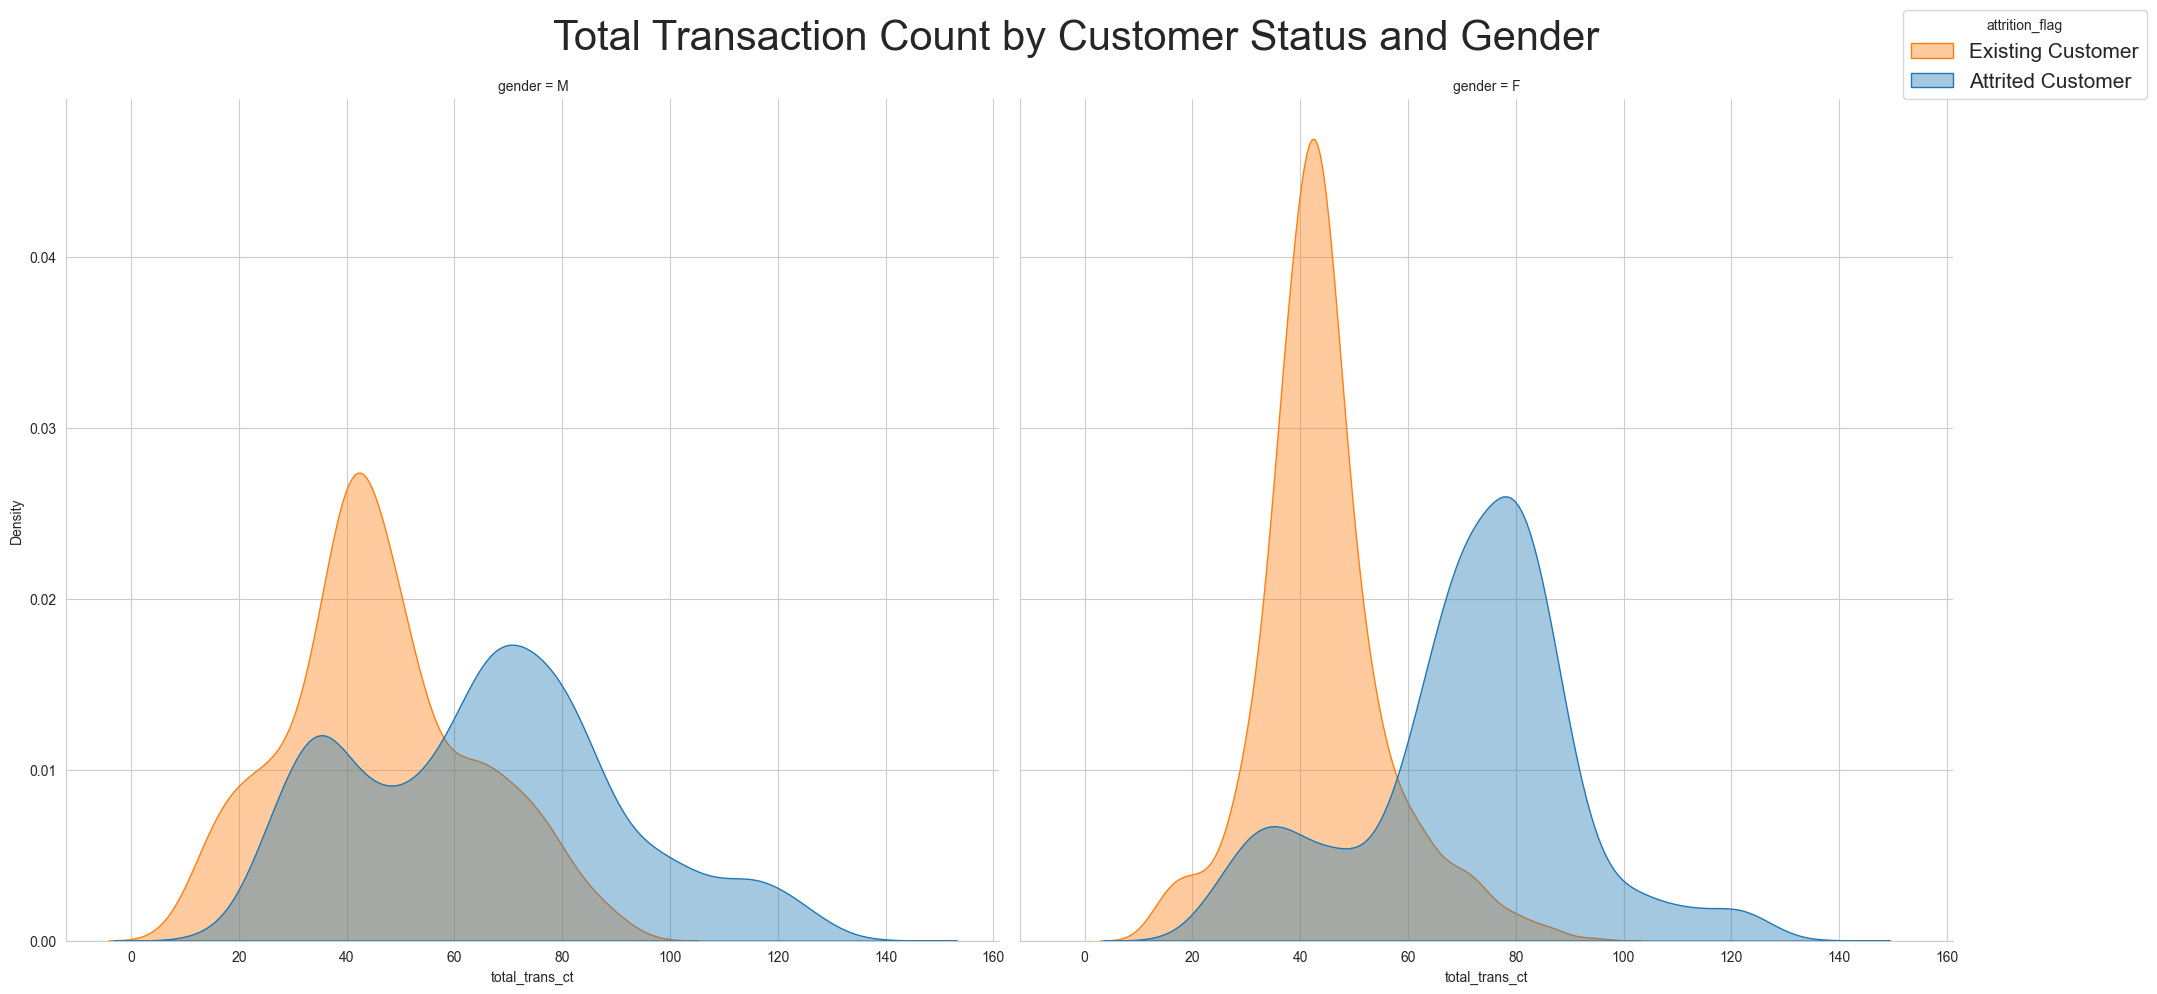

In [17]:
g = sns.displot(kind='kde', data=customers, x='total_trans_ct', hue="attrition_flag", 
                col='gender',  height=10, aspect=1, fill=True, common_norm=False, alpha=0.4)
g.fig.subplots_adjust(top=.9)
g._legend.remove()
g.fig.suptitle('Total Transaction Count by Customer Status and Gender', fontsize =30)
g.fig.legend(title='attrition_flag', fontsize = 15, loc='upper right', 
             labels=['Existing Customer', 'Attrited Customer']);


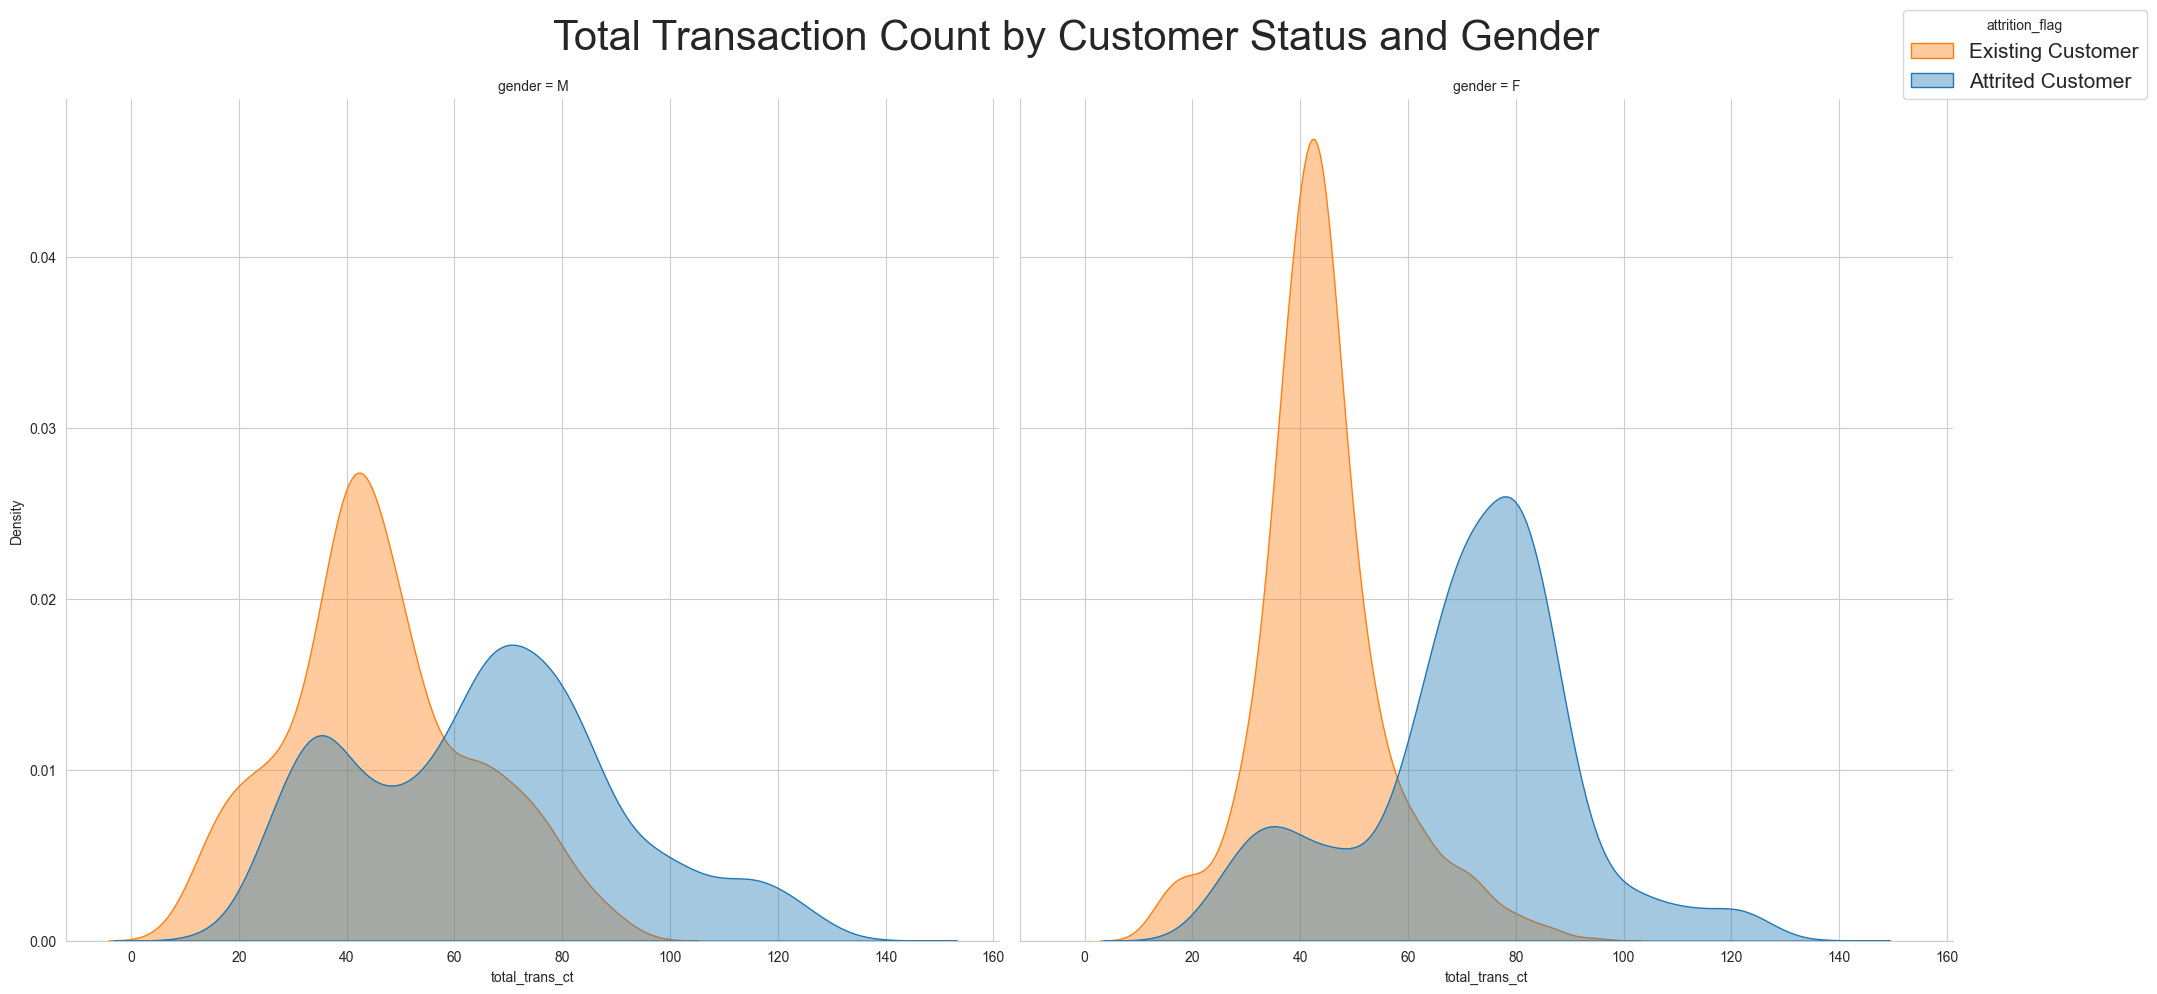

In [18]:
g = sns.displot(kind='kde', data=customers, x='total_trans_ct', hue="attrition_flag", 
                col='gender',  height=10, aspect=1, fill=True, common_norm=False, alpha=0.4)
g.fig.subplots_adjust(top=.9)
g._legend.remove()
g.fig.suptitle('Total Transaction Count by Customer Status and Gender', fontsize =30)
g.fig.legend(title='attrition_flag', fontsize = 15, loc='upper right', 
             labels=['Existing Customer', 'Attrited Customer']);

The total number of transactions for churned customers is more concentrated than existing customers. In the past 12 months, the events with the most transactions happened by attrited customers have occurred approximately 50 times, spending approximately 2500, which could be related to getting rewards when spending a specific amount or after certain amount of transactions.

## Correlation between variables

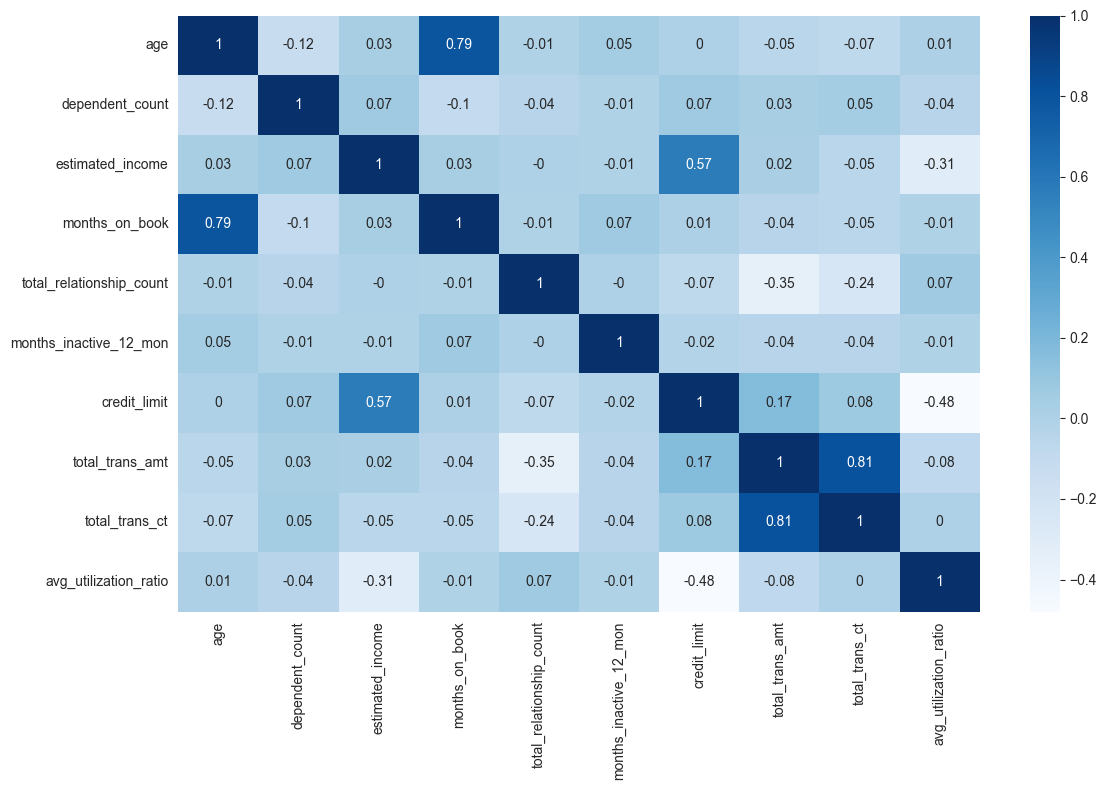

In [19]:
fig, ax = plt.subplots(figsize=(12,8))
sns.heatmap(round(customers.drop(['customer_id','attrition_flag','gender','education_level','marital_status'], axis=1).corr(), 2), cmap='Blues', annot=True, ax=ax)

plt.tight_layout()
plt.show()

Most of the variables present weak correlations between each other, but there are some we can highlight:

* Age is strongly correlated with how long the person has been a customer (months_on_book);
* Credit limit is positively correlated with the estimated income and negatively correlated with the average utilization ratio;
* The total number of transactions (total_trans_count) is strongly correlated with the total amount transitioned (total_trans_amount).

In [20]:
#Removing the customer's id before plotting the distributions
df_in=customers.drop('customer_id', axis=1)

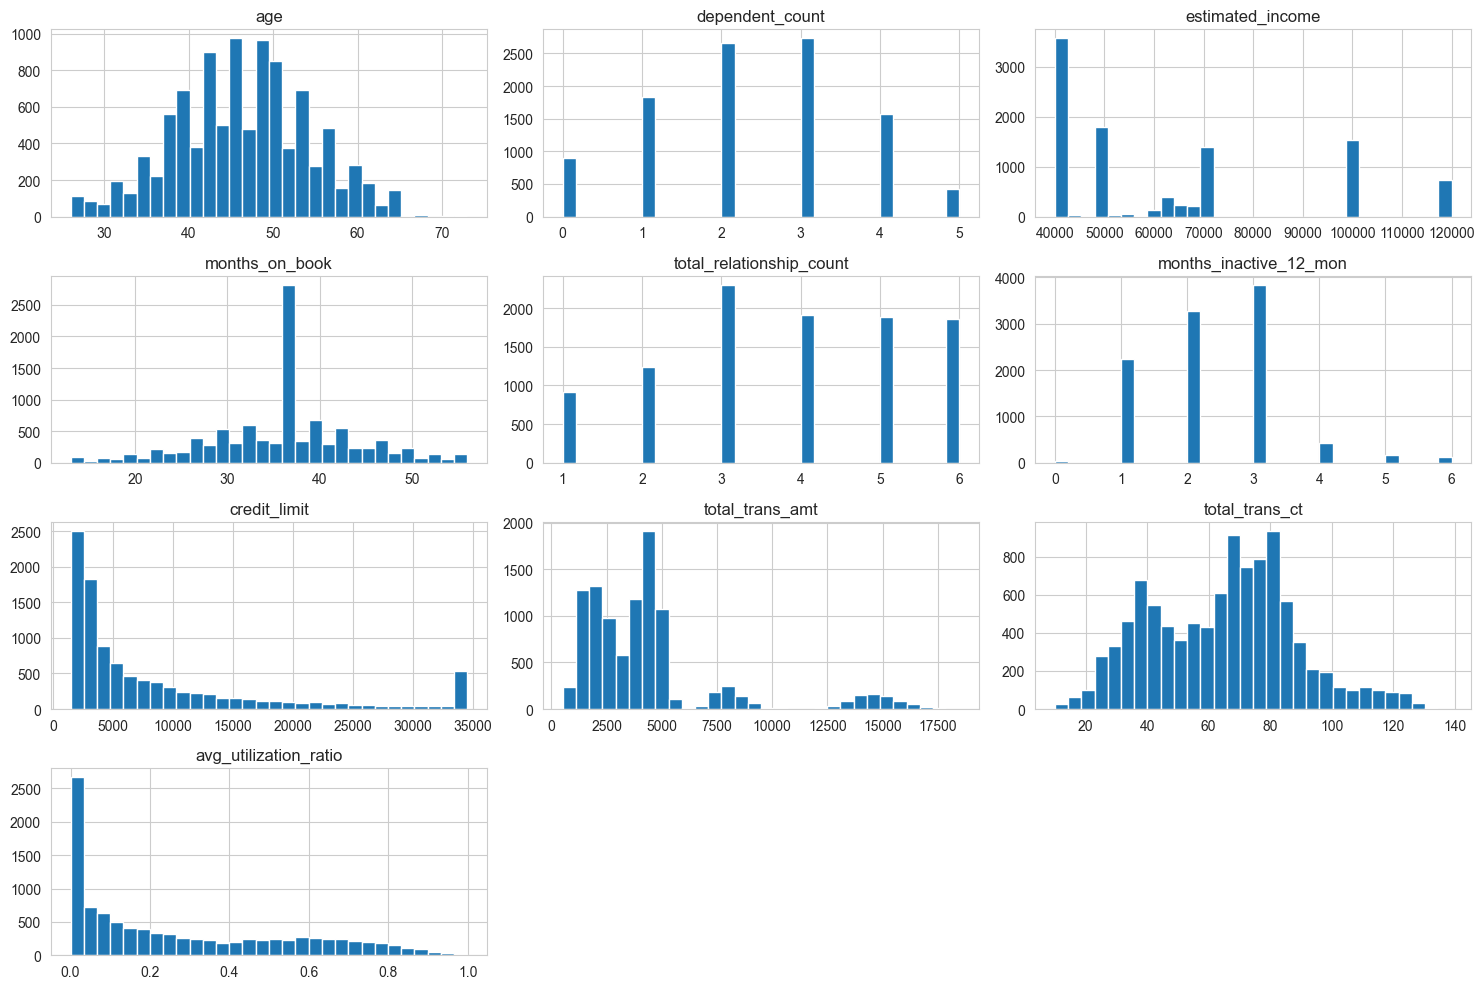

In [21]:
df_in.hist(bins=30, figsize=(15, 10))
plt.tight_layout();

Regarding distributions, we have a couple of them closer to a normal distribution, but most of them are skewed.

## Feature Engineering

We're now dealing with the 3 categorical variables.

The ```gender``` column is the easiest one. We'll use a lambda function to replace the values with ones and zeros.

We'll also be able to transform the ```education_level``` column to numeric. We'll use the ```replace()``` method to perform this task. This method will assign a value to each level of education:

* ```Unknown``` -0
* ```Uneducated``` - 1
* ```High School``` - 2
* ```College``` - 3
* ```Graduate``` - 4
* ```Post-Graduate``` - 5
* ```Doctorate``` - 6

Unfortunately, we can't do the same for this marital_status column as there is no level of magnitude between "Single", "Married" or "Divorced", for example. We can't say that any of them is higher or better than the others. Therefore, we'll use one-hot-encoding to create dummy variables from this column and then drop the original variable.

In [22]:
# Removing attrition_flag as we are no longer interested in this column
customers =customers.drop('attrition_flag', axis=1)

In [23]:
customers_modif = customers.copy()
customers_modif['gender'] = customers['gender'].apply(lambda x: 1 if x == 'M' else 0)
customers_modif.head()

,customer_id,age,gender,dependent_count,education_level,marital_status,estimated_income,months_on_book,total_relationship_count,months_inactive_12_mon,credit_limit,total_trans_amt,total_trans_ct,avg_utilization_ratio
0,768805383,45,1,3,High School,Married,70000,39,5,1,12691.0,1144,42,0.061
1,818770008,49,0,5,Graduate,Single,40000,44,6,1,8256.0,1291,33,0.105
2,713982108,51,1,3,Graduate,Married,100000,36,4,1,3418.0,1887,20,0.000
3,769911858,40,0,4,High School,Unknown,40000,34,3,4,3313.0,1171,20,0.760
4,709106358,40,1,3,Uneducated,Married,70000,21,5,1,4716.0,816,28,0.000


In [24]:
customers_modif.replace(to_replace={'Unknown':0,'Uneducated': 1, 'High School': 2, 'College':3,
                                    'Graduate': 4, 'Post-Graduate': 5, 'Doctorate':6}, inplace=True)
customers_modif['education_level'].head()

0    2
1    4
2    4
3    2
4    1
Name: education_level, dtype: int64

In [25]:
dummies = pd.get_dummies(customers_modif[['marital_status']], drop_first=True)

customers_modif = pd.concat([customers_modif, dummies], axis=1)
customers_modif.drop(['marital_status'], axis=1, inplace=True)

print(customers_modif.shape)
customers_modif.head()

(10127, 16)


,customer_id,age,gender,dependent_count,education_level,estimated_income,months_on_book,total_relationship_count,months_inactive_12_mon,credit_limit,total_trans_amt,total_trans_ct,avg_utilization_ratio,marital_status_Divorced,marital_status_Married,marital_status_Single
0,768805383,45,1,3,2,70000,39,5,1,12691.0,1144,42,0.061,0,1,0
1,818770008,49,0,5,4,40000,44,6,1,8256.0,1291,33,0.105,0,0,1
2,713982108,51,1,3,4,100000,36,4,1,3418.0,1887,20,0.000,0,1,0
3,769911858,40,0,4,2,40000,34,3,4,3313.0,1171,20,0.760,0,0,0
4,709106358,40,1,3,1,70000,21,5,1,4716.0,816,28,0.000,0,1,0


## Scaling the Data

First, we need to standardize the dataset. We'll use scikit-learn's StandardScaler() for this task.

In [28]:
# Droping customer_id columns and attrition_flag columns as is non numeric
X=customers_modif.drop(['customer_id'], axis=1)

In [29]:
scaler = StandardScaler()
scaler.fit(X)

X_scaled = scaler.transform(X)
X_scaled[:5]

array([[-0.16540558,  1.05995565,  0.50336813, -0.35402202,  0.26219285,
         0.38462088,  0.76394261, -1.32713603,  0.4466219 , -0.95970657,
        -0.97389518, -0.77588223, -0.2824051 ,  1.07733799, -0.79850685],
       [ 0.33357038, -0.9434357 ,  2.04319867,  0.82221847, -0.89921307,
         1.01071482,  1.40730617, -1.32713603, -0.04136665, -0.91643261,
        -1.35734038, -0.61627565, -0.2824051 , -0.92821381,  1.2523374 ],
       [ 0.58305837,  1.05995565,  0.50336813,  0.82221847,  1.42359876,
         0.00896451,  0.12057905, -1.32713603, -0.5736978 , -0.74098169,
        -1.91120566, -0.99715499, -0.2824051 ,  1.07733799, -0.79850685],
       [-0.78912553, -0.9434357 ,  1.2732834 , -0.35402202, -0.89921307,
        -0.24147306, -0.52278451,  1.64147829, -0.58525108, -0.95175829,
        -1.91120566,  1.75968594, -0.2824051 , -0.92821381, -0.79850685],
       [-0.78912553,  1.05995565,  0.50336813, -0.94214227,  0.26219285,
        -1.86931731,  0.76394261, -1.32713603, 

## Choosing K

It's time to decide on the number of clusters. We'll run the k-means algorithm considering a range from 1 to 10 possible Ks and store the results. Then, we'll plot the elbow curve that will help us find a final K.

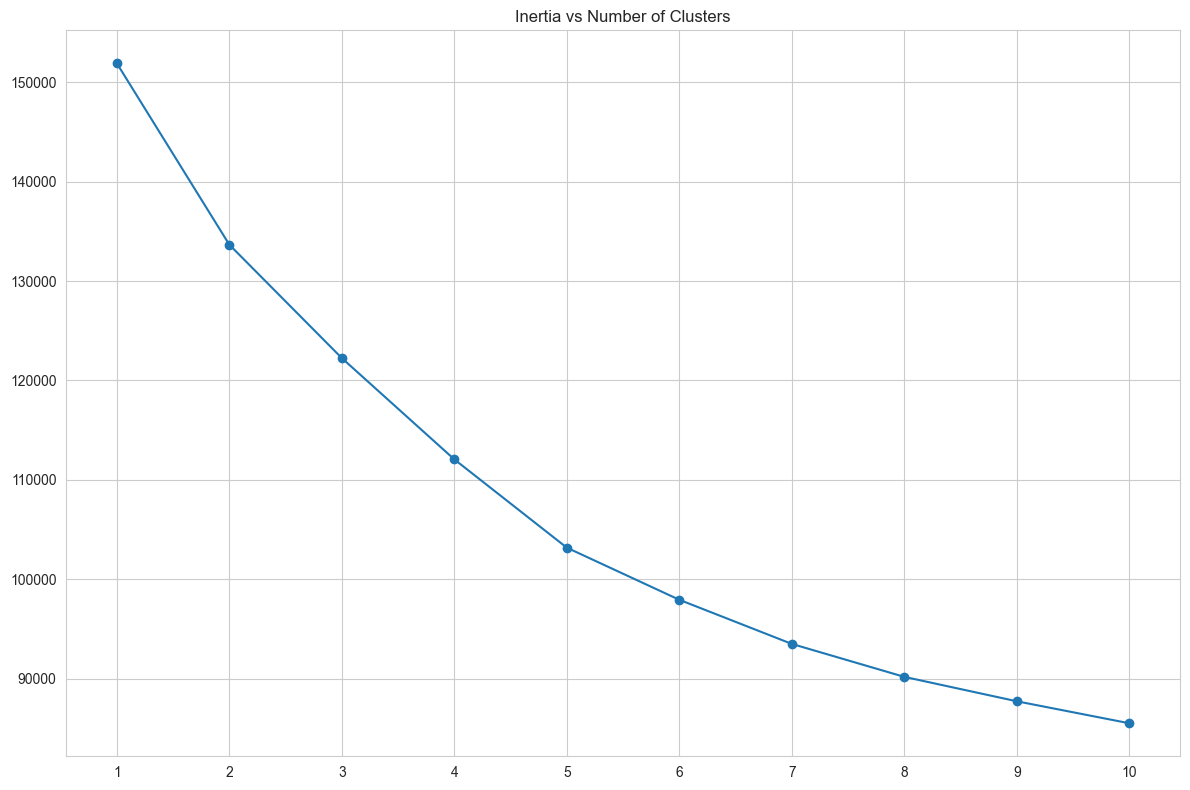

In [30]:
X = pd.DataFrame(X_scaled)
inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k)
    y = model.fit_predict(X)
    inertias.append(model.inertia_)
    
plt.figure(figsize=(12, 8))
plt.plot(range(1, 11), inertias, marker='o')
plt.xticks(ticks=range(1, 11), labels=range(1, 11))
plt.title('Inertia vs Number of Clusters')

plt.tight_layout()
plt.show()

In [31]:
model = KMeans(n_clusters=6)
y = model.fit_predict(X_scaled)

y

array([0, 2, 0, ..., 1, 1, 1], dtype=int32)

## Analyzing Results

Now, let's create a CLUSTER column in our original dataset so we can better understand the characteristics of each one.

In [32]:
customers['CLUSTER'] = y + 1
customers

,customer_id,age,gender,dependent_count,education_level,marital_status,estimated_income,months_on_book,total_relationship_count,months_inactive_12_mon,credit_limit,total_trans_amt,total_trans_ct,avg_utilization_ratio,CLUSTER
0,768805383,45,M,3,High School,Married,70000,39,5,1,12691.0,1144,42,0.061,1
1,818770008,49,F,5,Graduate,Single,40000,44,6,1,8256.0,1291,33,0.105,3
2,713982108,51,M,3,Graduate,Married,100000,36,4,1,3418.0,1887,20,0.000,1
3,769911858,40,F,4,High School,Unknown,40000,34,3,4,3313.0,1171,20,0.760,2
4,709106358,40,M,3,Uneducated,Married,70000,21,5,1,4716.0,816,28,0.000,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10122,772366833,50,M,2,Graduate,Single,50000,40,3,2,4003.0,15476,117,0.462,5
10123,710638233,41,M,2,Unknown,Divorced,50000,25,4,2,4277.0,8764,69,0.511,6
10124,716506083,44,F,1,High School,Married,40000,36,5,3,5409.0,10291,60,0.000,2
10125,717406983,30,M,2,Graduate,Unknown,50000,36,4,3,5281.0,8395,62,0.000,2


In [33]:
customers['CLUSTER'].value_counts()

2    2705
3    2343
1    2042
4    1362
5     941
6     734
Name: CLUSTER, dtype: int64

We can see that cluster 2 is the largest while cluster 6 is the smallest.

Considering the numeric variable only, we'll check on the average value of each variable per cluster. We just need to group the data and plot a bar chart for each column.

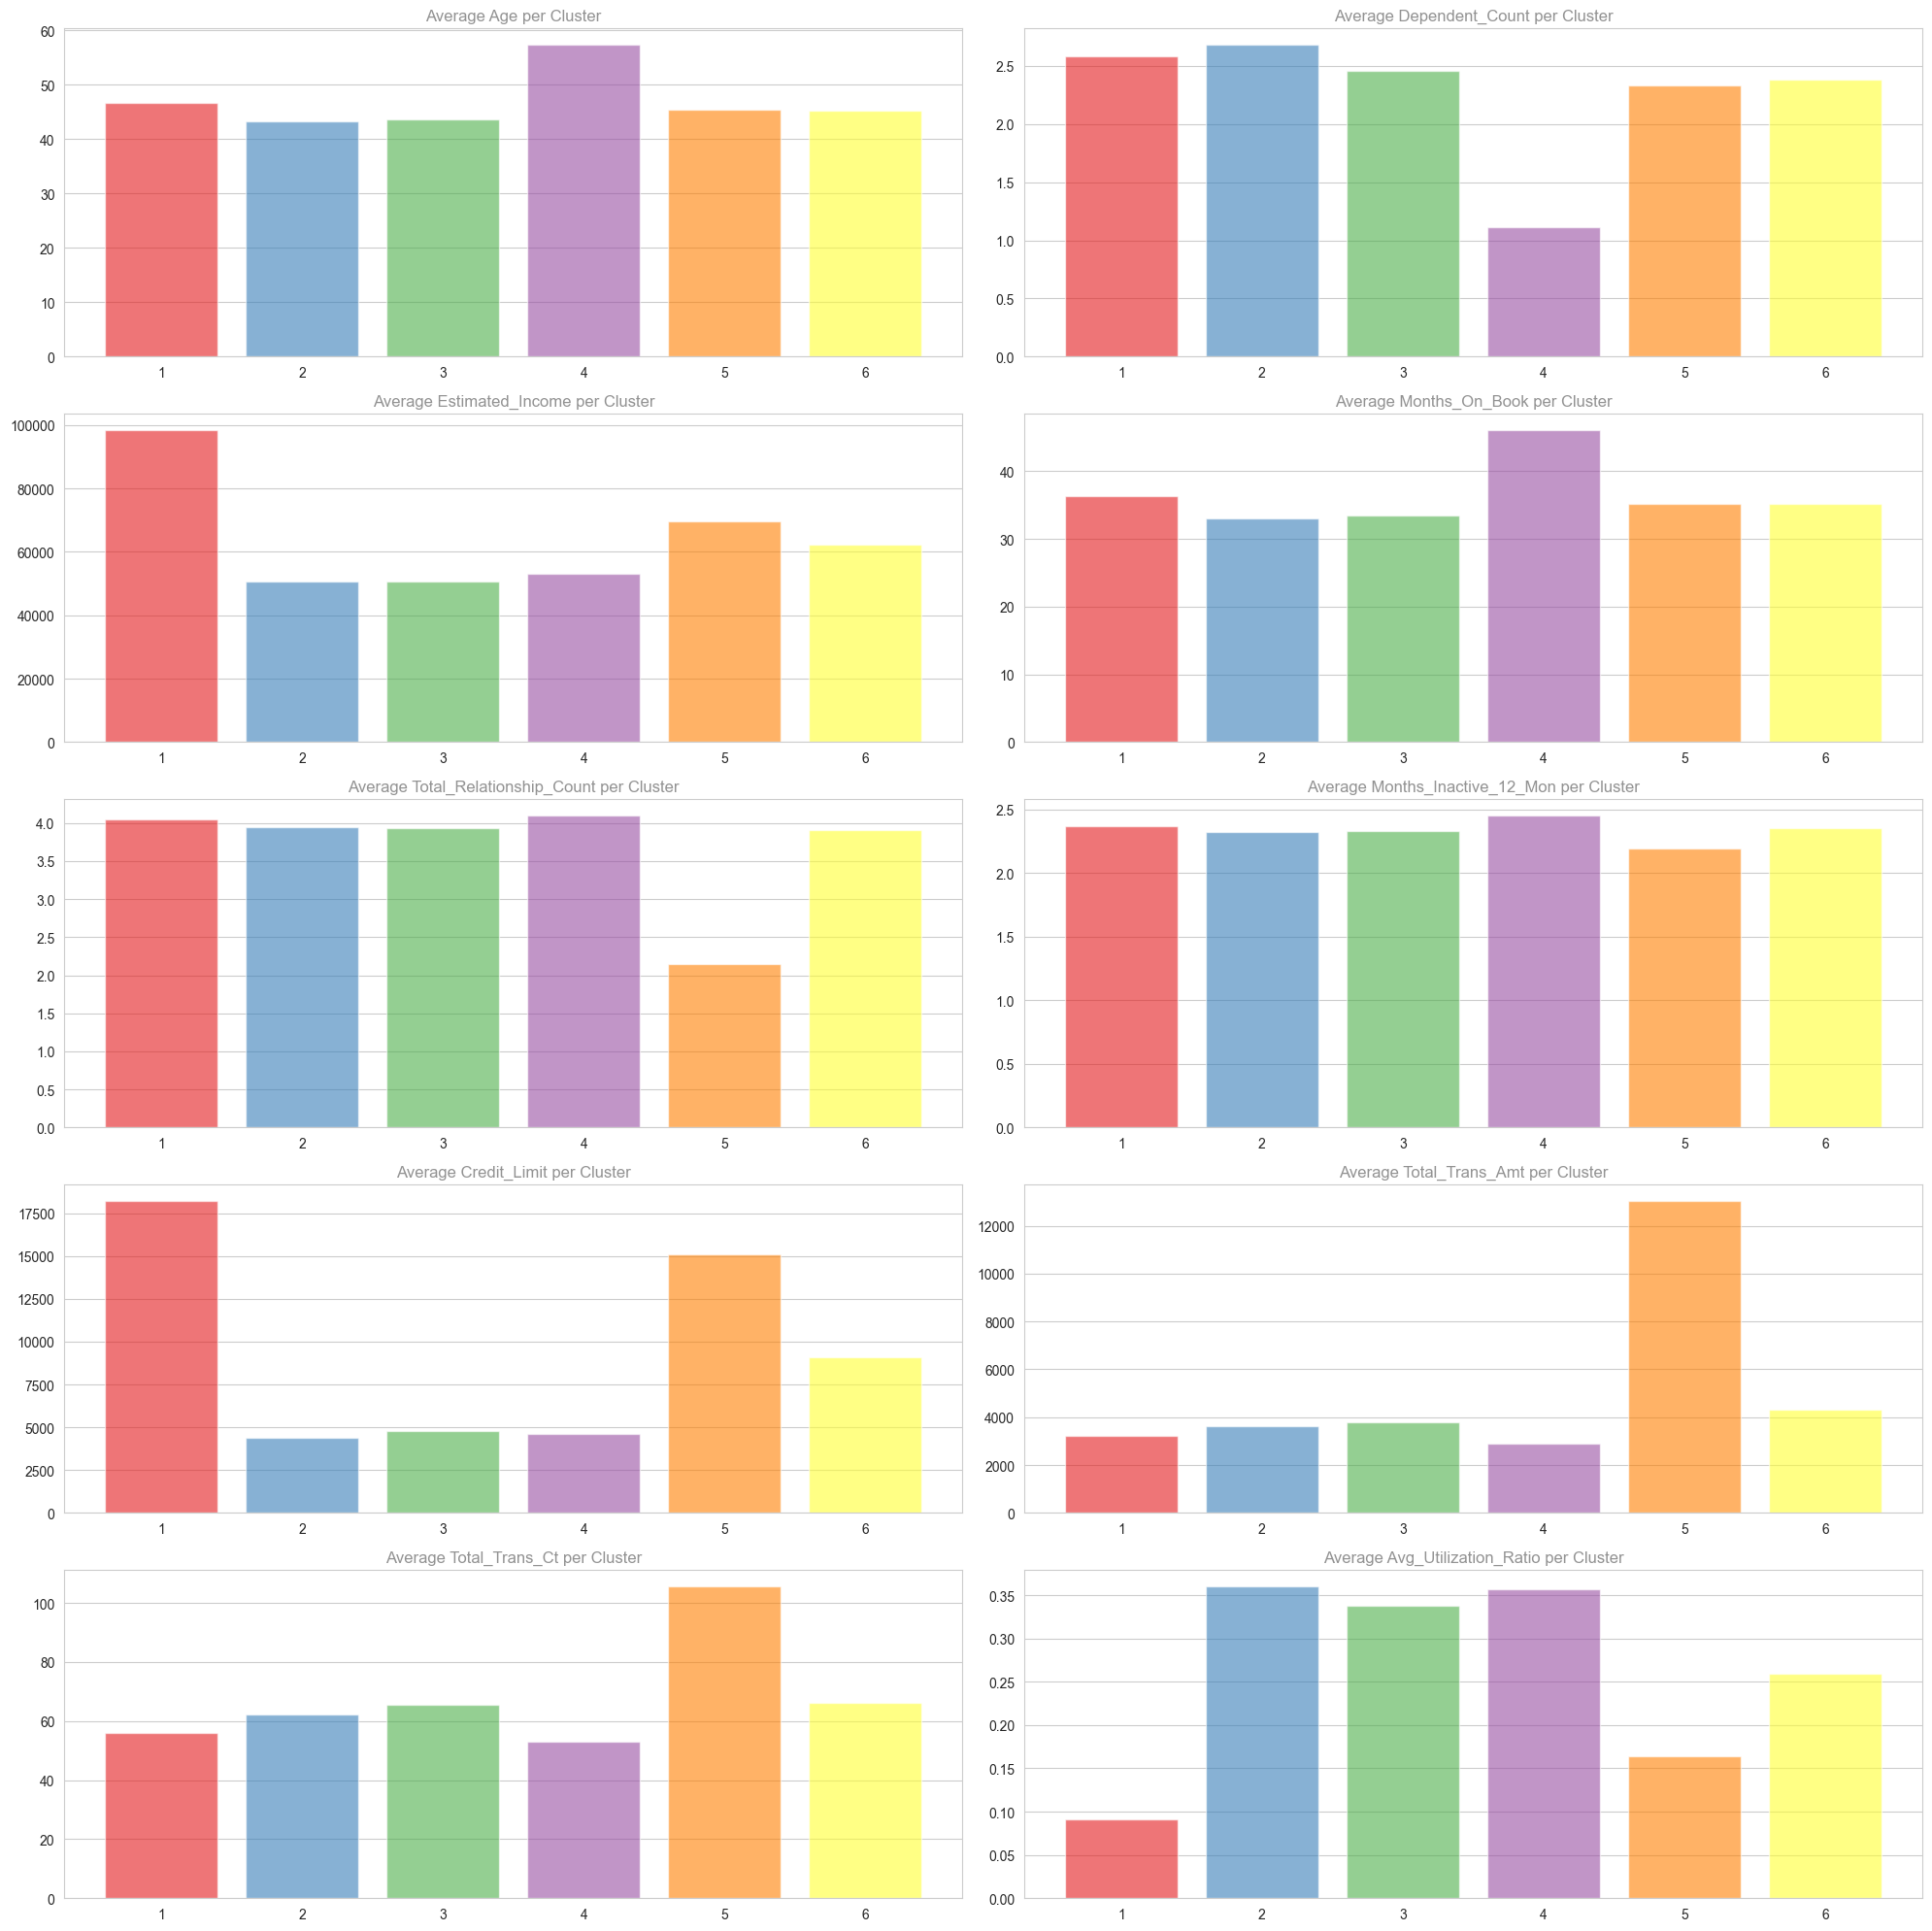

In [34]:
numeric_columns = customers.select_dtypes(include=np.number).drop(['customer_id', 'CLUSTER'], axis=1).columns

fig = plt.figure(figsize=(20, 20))
for i, column in enumerate(numeric_columns):
    df_plot = customers.groupby('CLUSTER')[column].mean()
    ax = fig.add_subplot(5, 2, i+1)
    ax.bar(df_plot.index, df_plot, color=sns.color_palette('Set1'), alpha=0.6)
    ax.set_title(f'Average {column.title()} per Cluster', alpha=0.5)
    ax.xaxis.grid(False)
    
plt.tight_layout()
plt.show()

For those numerical variables with higher correlations we saw earlier, we can also use a scatter plot to visualize this correlation grouped by clusters and analyze how the clusters change between each area of the chart.

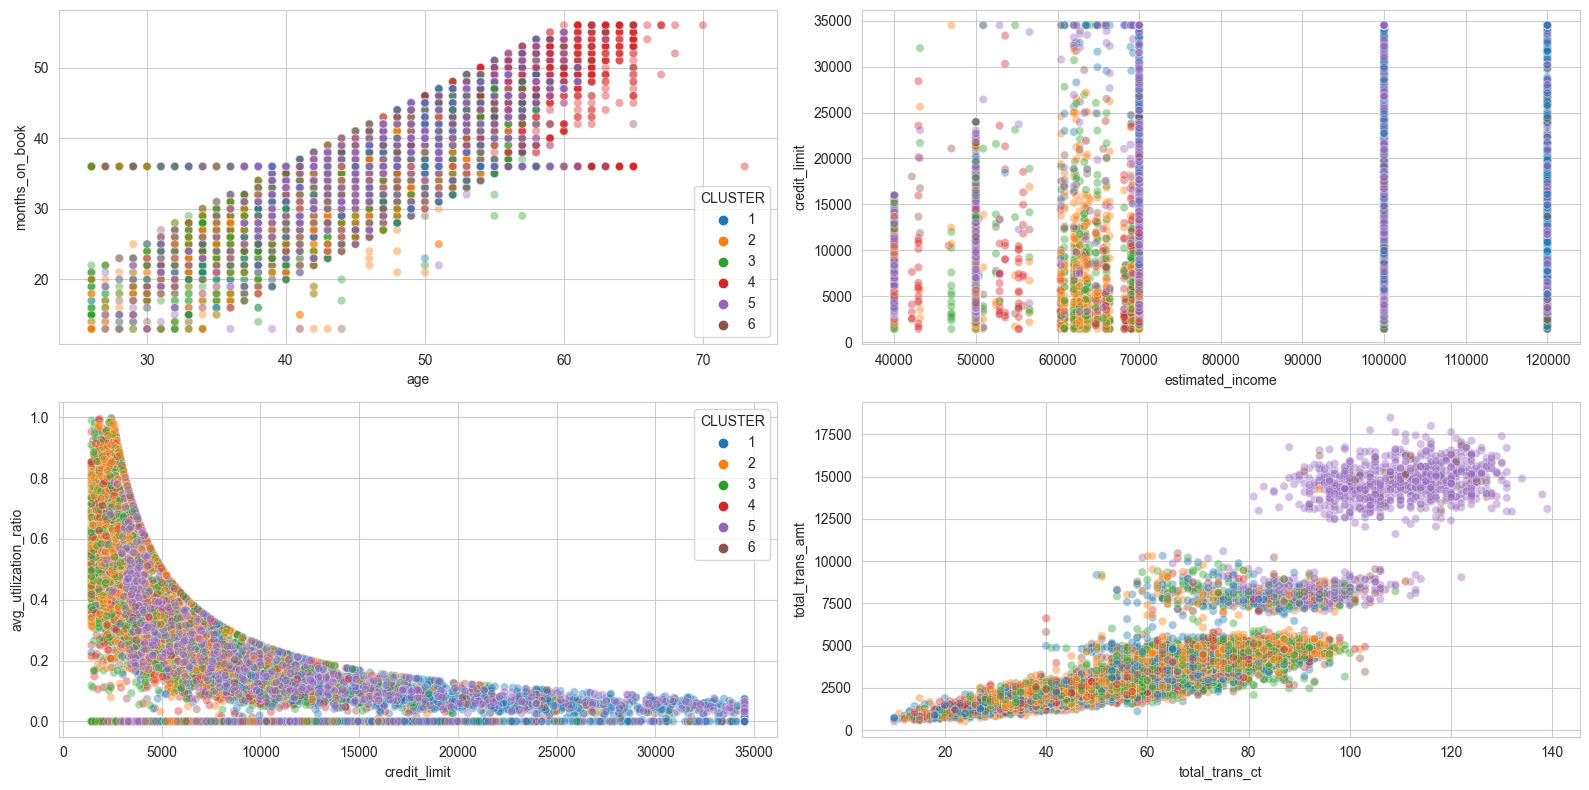

In [35]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 8))
sns.scatterplot(x='age', y='months_on_book', hue='CLUSTER', data=customers, palette='tab10', alpha=0.4, ax=ax1)
sns.scatterplot(x='estimated_income', y='credit_limit', hue='CLUSTER', data=customers, palette='tab10', alpha=0.4, ax=ax2, legend=False)
sns.scatterplot(x='credit_limit', y='avg_utilization_ratio', hue='CLUSTER', data=customers, palette='tab10', alpha=0.4, ax=ax3)
sns.scatterplot(x='total_trans_ct', y='total_trans_amt', hue='CLUSTER', data=customers, palette='tab10', alpha=0.4, ax=ax4, legend=False)

plt.tight_layout()
plt.show()

#### We can draw some early conclusions considering only the numeric variables.

For instance, Cluster 4 has the highest amount of money transactioned, while Cluster 2 has the lowest credit limit and estimated income and the highest utilization rate. Cluster 5 has the highest credit limit. Older clients are grouped in Cluster 4.

For the categorical columns, we'll plot the percentual distribution of each variable in each cluster. This will allow us to verify if a particular cluster is mostly composed of men, or of married people only, for example.

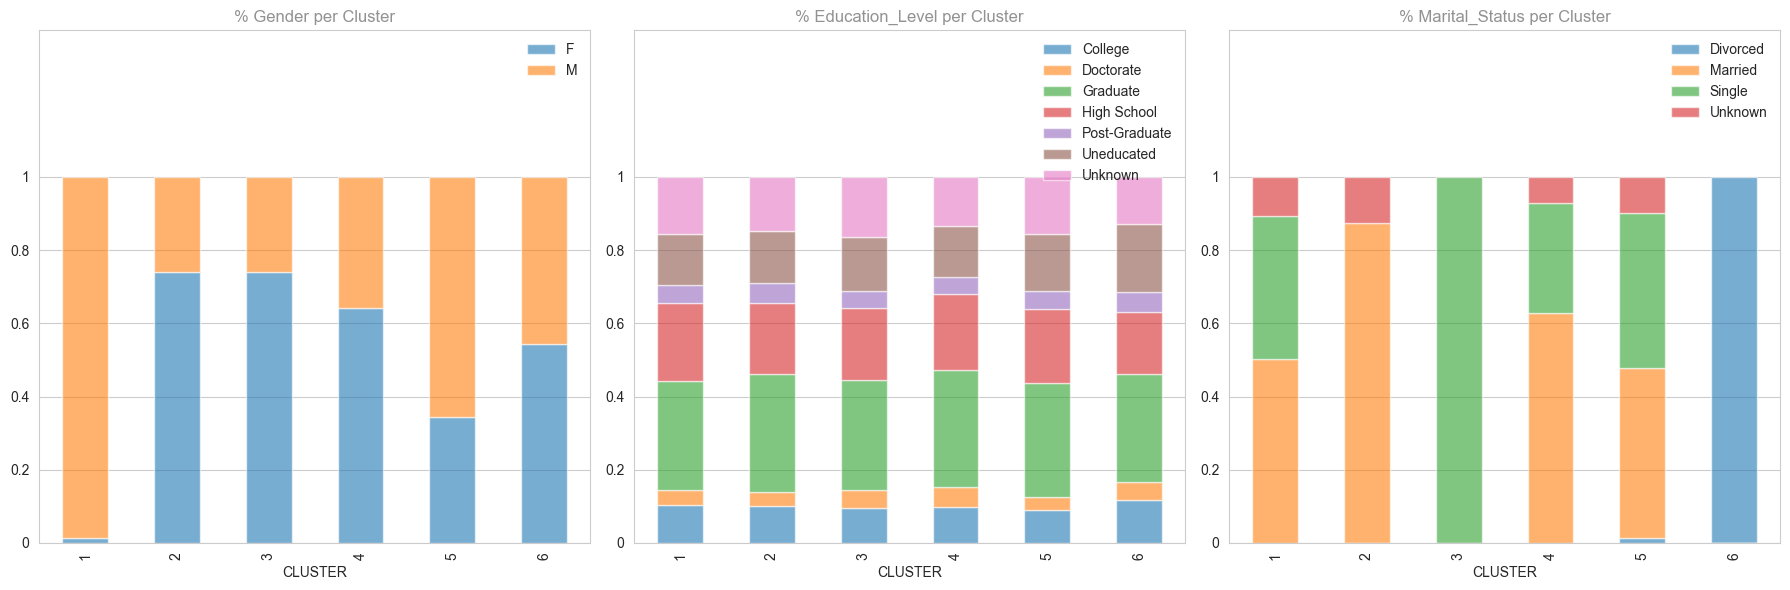

In [37]:
cat_columns = customers.select_dtypes(include=['object'])

fig = plt.figure(figsize=(18, 6))
for i, col in enumerate(cat_columns):
    plot_df = pd.crosstab(index=customers['CLUSTER'], columns=customers[col], values=customers[col], aggfunc='size', normalize='index')
    ax = fig.add_subplot(1,3,i+1)
    plot_df.plot.bar(stacked=True, ax=ax, alpha=0.6)
    ax.set_title(f'% {col.title()} per Cluster', alpha=0.5)

    ax.set_ylim(0, 1.4)
    ax.legend(frameon=False)
    ax.xaxis.grid(False)
    
    labels = [0, 0.2, 0.4, 0.6, 0.8, 1]
    ax.yaxis.set_major_locator(mticker.FixedLocator(labels))
    ax.set_yticklabels(labels)

plt.tight_layout()
plt.show()

Considering the categorical variables, we notice that the education level is well divided between clusters.

In other highlights, Cluster 2 is composed almost entirely of married people, while we don't know the marital status of anybody in Cluster 3. Cluster 4 is almost completely male and CLuster 6 is 100% made of single people.


## Conclusion

In [43]:
# List of customers and clusters
customers.groupby('CLUSTER')['customer_id'].count().sort_values(ascending=False)

CLUSTER
2    2705
3    2343
1    2042
4    1362
5     941
6     734
Name: customer_id, dtype: int64

As demanded by the company, we now have listed the most important characteristics of each cluster. We could also some suggestions and insights into each one of them.

In the end, we have the list of customers with a cluster assigned to each one.

***Cluster 1***

***Characteristics*** 

Mostly men, high dependent count, high credit limit, low of total transaction, low number of transactions, low utilization rate.

***Insight*** 

People with low volume spent on the card, but do not use it on a daily basis. Could be incentivized to use it more often.

***Cluster 2***

***Characteristics*** 

Mostly women, mostly married, mid-range estimated income, high dependent count low credit limit, mid-range amount transactioned, high utilization rate.

***Insight*** 

Married people (majority women) with low income and limit but use the card too often. Could be given a bit more credit limit. Largest cluster.

***Cluster 3***

***Characteristics*** 

Mostly women, slighltly higher credit limit  than cluster 2 however it keeps on the low range, high utilization rate, marital status single, second largest cluster.

***Insight***  

Mostly women with low credit limits but use the card too often. Could be combined with Cluster 2.

***Cluster 4***

***Characteristics*** 

Older cluster of customers, Gender well divided, mostly single and married with a low number of unknowns, high age, low estimated income, low dependent count, cluster with highest average per months on books, low credit limit, low amount transitioned; high utilization rate (highest cluster).

***Insight***  

People (majority female) with low income and credit limits and uses their card regularly. Could be given more credit or create a finance class to better use products and use credit cards. Long time customer. Could receive benefits to spend more money.

***Cluster 5***

***Characteristics***

Mostly men, mostly single and married with a low number of divorced, low dependent count, high credit limit, high amount transitioned, low utilization rate.

***Insight*** 

Long-time customers. high credit limit and transactions, do not use card regularly. Could be incentivized to use it. 

***Cluster 6***

***Characteristics*** 

Gender well divided, 100% divorced people, high estimated income, mid range credit limit, l high utilization rate.

***Insight***  

Divorced (mostly men) people that use their card a lot with mid-range credit limits and income. Could be given a bit more credit limit.

